
# Approximate Nearest Neighbor Search with FAISS and HNSW

This notebook benchmarks exact and approximate dense vector retrieval using the SciFact dataset.

We compare two FAISS indexes:

- **IndexFlatIP:** Exact nearest neighbor search using inner product.
- **IndexHNSWFlat:** Approximate nearest neighbor search using a Hierarchical Navigable Small World (HNSW) graph.

Our experiments evaluate:

1. Retrieval correctness against an exact search baseline.
2. ANN Recall@10.
3. Search latency.
4. The recall-latency trade-off across different `efSearch` values.
5. Serialized index size.

## 1. Loading Document Embeddings

We load the normalized SciFact document embeddings generated in Notebook 02:

`data/scifact_embeddings.npy`

The embedding matrix contains 5,183 documents, each represented by a 384-dimensional vector.

We also inspect the FAISS version, embedding shape, data type, and vector norm to verify the input data before building the indexes.


In [15]:
import numpy as np
import faiss
from pathlib import Path

# Locate the project directory
cwd = Path.cwd()

if cwd.name == "notebooks":
    project_dir = cwd.parent
else:
    project_dir = cwd

data_dir = project_dir / "data"
embedding_path = data_dir / "scifact_embeddings.npy"

# Load document embeddings
document_embeddings = np.load(embedding_path)

print("FAISS version:", faiss.__version__)
print("Embedding shape:", document_embeddings.shape)
print("Data type:", document_embeddings.dtype)
print("First document norm:", np.linalg.norm(document_embeddings[0]))

FAISS version: 1.16.0
Embedding shape: (5183, 384)
Data type: float32
First document norm: 1.0000001



## 2. Building an Exact FAISS Index

We construct a FAISS `IndexFlatIP` to perform exact nearest neighbor search using inner product similarity.

Because the document and query embeddings are L2-normalized, inner product is equivalent to cosine similarity:

$$
\operatorname{cosine}(q,d) = \hat{q} \cdot \hat{d}
$$

`IndexFlatIP` compares each query against all indexed document vectors without approximate candidate selection.

We add all 5,183 document embeddings to the index and verify its size and dimensionality.

This index serves as the **exact nearest neighbor baseline** for evaluating HNSW.


In [2]:
# Get embedding dimensions
num_docs, dim = document_embeddings.shape

# Create an exact inner product index
flat_index = faiss.IndexFlatIP(dim)

# Add document vectors to the index
flat_index.add(document_embeddings)

print("Number of documents:", flat_index.ntotal)
print("Embedding dimension:", flat_index.d)
print("Is trained:", flat_index.is_trained)

Number of documents: 5183
Embedding dimension: 384
Is trained: True



## 3. Verifying Exact Search Correctness

We load the same Sentence Transformer model used in Notebook 02 and encode a sample query into a normalized embedding.

We then retrieve the Top-10 documents using FAISS `IndexFlatIP`.

To verify the implementation, we independently compute similarity scores using NumPy matrix-vector multiplication:

$$
s = D\hat{q}
$$

where $D$ is the normalized document embedding matrix and $\hat{q}$ is the normalized query embedding.

We compare the FAISS results against NumPy using:

- `np.array_equal()` to check whether the Top-10 document indices match.
- `np.allclose()` to check whether the similarity scores are numerically equivalent.

This confirms that the FAISS exact search implementation agrees with our NumPy-based retrieval baseline for the sample query.


In [3]:
from sentence_transformers import SentenceTransformer

# Load the same embedding model used in Notebook 02
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

# Use a sample query
query = "0-dimensional biomaterials show inductive properties."

# Encode and normalize the query
query_embedding = model.encode(
    [query],
    convert_to_numpy=True,
    normalize_embeddings=True
)

# Search for the top 10 documents
k = 10
distances, indices = flat_index.search(query_embedding, k)

print("Query embedding shape:", query_embedding.shape)
print("Distances shape:", distances.shape)
print("Indices shape:", indices.shape)

print("\nTop-10 similarity scores:")
print(distances[0])

print("\nTop-10 document indices:")
print(indices[0])

C:\Users\weiting\anaconda3\envs\dense-retrieval\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2506.72it/s]


Query embedding shape: (1, 384)
Distances shape: (1, 10)
Indices shape: (1, 10)

Top-10 similarity scores:
[0.35401332 0.33061412 0.2921809  0.29161578 0.29155606 0.29090577
 0.2903912  0.275367   0.27412987 0.26613754]

Top-10 document indices:
[4132  766  697 1838 4241 2723 5115  166 2981  320]


In [4]:
# Compute similarity scores using NumPy
numpy_scores = document_embeddings @ query_embedding[0]

# Retrieve Top-10 using NumPy
numpy_top10 = np.argsort(numpy_scores)[::-1][:10]

# Compare FAISS and NumPy results
print("FAISS Top-10:", indices[0])
print("NumPy Top-10:", numpy_top10)

print(
    "Same Top-10:",
    np.array_equal(indices[0], numpy_top10)
)

print(
    "Same scores:",
    np.allclose(
        distances[0],
        numpy_scores[numpy_top10],
        atol=1e-5
    )
)

FAISS Top-10: [4132  766  697 1838 4241 2723 5115  166 2981  320]
NumPy Top-10: [4132  766  697 1838 4241 2723 5115  166 2981  320]
Same Top-10: True
Same scores: True



## 4. Building an HNSW Index

We construct an approximate nearest neighbor index using FAISS `IndexHNSWFlat`.

HNSW (Hierarchical Navigable Small World) organizes vectors into a multi-layer proximity graph, enabling approximate nearest neighbor search without exhaustively comparing every document.

We configure the index using three parameters:

- **M = 16:** Controls the graph connectivity during index construction.
- **efConstruction = 100:** Controls the candidate search breadth during index construction.
- **efSearch = 32:** Controls the candidate search breadth during query processing.

Increasing `efSearch` generally improves retrieval accuracy but requires more search computation.

We use inner product similarity to remain consistent with the exact FAISS baseline.

After adding the document embeddings, we verify the index size, dimensionality, and HNSW parameters.


In [5]:
# HNSW parameters
M = 16
ef_construction = 100
ef_search = 32

# Create HNSW index using inner product
hnsw_index = faiss.IndexHNSWFlat(
    dim,
    M,
    faiss.METRIC_INNER_PRODUCT
)

# Configure index construction
hnsw_index.hnsw.efConstruction = ef_construction

# Add document vectors
hnsw_index.add(document_embeddings)

# Configure search
hnsw_index.hnsw.efSearch = ef_search

print("Number of documents:", hnsw_index.ntotal)
print("Embedding dimension:", hnsw_index.d)
print("M:", M)
print("efConstruction:", hnsw_index.hnsw.efConstruction)
print("efSearch:", hnsw_index.hnsw.efSearch)

Number of documents: 5183
Embedding dimension: 384
M: 16
efConstruction: 100
efSearch: 32



## 5. Evaluating Approximate Search with ANN Recall@10

We compare the Top-10 documents returned by HNSW against the exact Top-10 documents returned by `IndexFlatIP`.

**ANN Recall@10** measures how many exact nearest neighbors are successfully recovered by the approximate search.

For a query $q$:

$$
\operatorname{ANNRecall@K}(q) =
\frac{|A_q^K \cap E_q^K|}{K}
$$

where:

- $A_q^K$ is the set of Top-K documents returned by HNSW.
- $E_q^K$ is the set of Top-K documents returned by exact search.
- $K$ is the number of retrieved documents.

For example, if HNSW retrieves 9 of the exact Top-10 documents:

$$
\operatorname{ANNRecall@10} = \frac{9}{10} = 0.9
$$

**Important:** ANN Recall@10 is different from the retrieval Recall@10 evaluated in Notebook 02.

- **Retrieval Recall@10** compares retrieved documents against SciFact ground-truth relevance judgments.
- **ANN Recall@10** compares approximate search results against exact nearest neighbor results.

ANN Recall evaluates how closely HNSW approximates exact vector search, not whether the retrieved documents are relevant to the original scientific query.


In [6]:
# Search using HNSW
hnsw_distances, hnsw_indices = hnsw_index.search(
    query_embedding,
    k=10
)

# Compare results
print("Exact Top-10:", indices[0])
print("HNSW Top-10: ", hnsw_indices[0])

# Calculate ANN Recall@10
exact_set = set(indices[0])
hnsw_set = set(hnsw_indices[0])

hits = len(exact_set & hnsw_set)

ann_recall = hits / 10

print(f"\nANN Recall@10: {ann_recall:.4f}")

Exact Top-10: [4132  766  697 1838 4241 2723 5115  166 2981  320]
HNSW Top-10:  [4132  766  697 1838 4241 2723 5115  166 2981 1212]

ANN Recall@10: 0.9000



## 6. Evaluating ANN Recall Across All Queries

We load the SciFact evaluation queries and relevance judgments.

After selecting unique query IDs from the test relevance judgments, we encode all 300 evaluation queries using the same Sentence Transformer model.

We then perform Top-10 retrieval using both indexes:

- `IndexFlatIP` produces the exact nearest neighbors.
- `IndexHNSWFlat` produces the approximate nearest neighbors.

For each query, we calculate ANN Recall@10 by comparing the two sets of retrieved document indices.

The mean ANN Recall@10 is:

$$
\operatorname{MeanANNRecall@10} =
\frac{1}{Q}\sum_{i=1}^{Q}
\operatorname{ANNRecall@10}(q_i)
$$

where $Q$ is the number of evaluated queries.

With `efSearch = 32`, our experiment achieved a mean ANN Recall@10 of approximately **0.9730**.


In [7]:
from datasets import load_dataset

# Load SciFact queries and relevance judgments
queries = load_dataset("BeIR/scifact", "queries", split="queries")
qrels = load_dataset("BeIR/scifact-qrels", split="test")

# Create query ID to text mapping
query_dict = {
    str(query["_id"]): query["text"]
    for query in queries
}

# Select the 300 evaluation queries
eval_query_ids = [
    str(row["query-id"])
    for row in qrels
]

# Remove duplicate query IDs while preserving order
eval_query_ids = list(dict.fromkeys(eval_query_ids))

eval_query_texts = [
    query_dict[query_id]
    for query_id in eval_query_ids
]

# Encode all evaluation queries
query_embeddings = model.encode(
    eval_query_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Evaluation queries:", len(eval_query_ids))
print("Query embeddings shape:", query_embeddings.shape)

Batches: 100%|██████████| 10/10 [00:03<00:00,  3.03it/s]

Evaluation queries: 300
Query embeddings shape: (300, 384)


In [8]:
k = 10

# Exact search for all queries
exact_distances, exact_indices = flat_index.search(
    query_embeddings, k
)

# HNSW search for all queries
hnsw_distances, hnsw_indices = hnsw_index.search(
    query_embeddings, k
)

# Calculate ANN Recall@10 for each query
ann_recall_scores = []

for i in range(len(query_embeddings)):
    exact_set = set(exact_indices[i])
    hnsw_set = set(hnsw_indices[i])

    hits = len(exact_set & hnsw_set)
    recall = hits / k

    ann_recall_scores.append(recall)

# Calculate mean ANN Recall@10
mean_ann_recall = np.mean(ann_recall_scores)

print(f"Mean ANN Recall@10: {mean_ann_recall:.4f}")

Mean ANN Recall@10: 0.9730



## 7. Benchmarking Search Latency

We compare the search performance of `IndexFlatIP` and `IndexHNSWFlat`.

To obtain more consistent measurements, we:

1. Configure FAISS to use a single CPU thread.
2. Perform a warm-up search before timing.
3. Measure search execution time using `time.perf_counter()`.
4. Repeat each benchmark five times.
5. Calculate the average search time per query.

The average time per query is calculated as:

$$
T_{\text{avg}} =
\frac{T_{\text{batch}}}{Q} \times 1000
$$

where:

- $T_{\text{batch}}$ is the average batch execution time in seconds.
- $Q$ is the number of queries in the batch.
- $T_{\text{avg}}$ is the average search time in milliseconds per query.

This metric represents **batch search time divided by the number of queries**, rather than independently measured single-query latency.

We also calculate the speedup:

$$
\operatorname{Speedup} =
\frac{T_{\text{exact}}}{T_{\text{HNSW}}}
$$

In our initial benchmark with `efSearch = 32`:

| Index | Time (ms/query) |
|---|---:|
| IndexFlatIP | 3.6973 |
| IndexHNSWFlat | 0.4281 |

HNSW achieved approximately **8.64x speedup** over exact search in this measurement.

These timings are specific to the benchmark environment and should not be interpreted as universal performance guarantees.


In [9]:
import time

# Use one CPU thread for a controlled comparison
faiss.omp_set_num_threads(1)

def benchmark_search(index, queries, k=10, runs=5):

    # Warm-up
    index.search(queries, k)

    times = []

    for _ in range(runs):
        start = time.perf_counter()

        index.search(queries, k)

        end = time.perf_counter()
        times.append(end - start)

    avg_total_time = np.mean(times)

    # Convert to milliseconds per query
    avg_latency_ms = avg_total_time / len(queries) * 1000

    return avg_latency_ms


flat_latency = benchmark_search(
    flat_index, query_embeddings
)

hnsw_latency = benchmark_search(
    hnsw_index, query_embeddings
)

print(f"Exact Search: {flat_latency:.4f} ms/query")
print(f"HNSW Search:  {hnsw_latency:.4f} ms/query")
print(f"Speedup: {flat_latency / hnsw_latency:.2f}x")

Exact Search: 3.6973 ms/query
HNSW Search:  0.4281 ms/query
Speedup: 8.64x



## 8. Exploring the Recall-Latency Trade-off

The HNSW `efSearch` parameter controls the breadth of candidate exploration during approximate nearest neighbor search.

A smaller `efSearch` generally reduces search computation but may miss some exact nearest neighbors.

A larger `efSearch` generally improves ANN Recall@10 at the cost of additional search time.

We evaluate six configurations:

`efSearch = [10, 16, 32, 64, 128, 256]`

For each configuration, we:

1. Update the HNSW `efSearch` parameter.
2. Retrieve the Top-10 documents for all 300 queries.
3. Calculate mean ANN Recall@10 against the exact FAISS results.
4. Measure average batch search time per query.
5. Store the results for comparison.

### Experimental Results

| efSearch | ANN Recall@10 | Time (ms/query) |
|---:|---:|---:|
| 10 | 0.8777 | 0.2016 |
| 16 | 0.9303 | 0.2521 |
| 32 | 0.9730 | 0.4002 |
| 64 | 0.9917 | 0.6347 |
| 128 | 0.9983 | 1.0796 |
| 256 | 1.0000 | 2.0681 |

The results demonstrate the trade-off between approximate search accuracy and computational cost.

Increasing `efSearch` improves ANN Recall@10, but the additional accuracy comes with higher search latency.

The benchmark results are saved to:

`results/hnsw_benchmark.csv`


In [10]:
ef_search_values = [10, 16, 32, 64, 128, 256]

benchmark_results = []

for ef in ef_search_values:

    # Change HNSW search parameter
    hnsw_index.hnsw.efSearch = ef

    # Search all 300 queries
    _, ann_indices = hnsw_index.search(
        query_embeddings, k=10
    )

    # Calculate mean ANN Recall@10
    recall_scores = []

    for i in range(len(query_embeddings)):
        exact_set = set(exact_indices[i])
        ann_set = set(ann_indices[i])

        recall = len(exact_set & ann_set) / 10
        recall_scores.append(recall)

    mean_recall = np.mean(recall_scores)

    # Measure search latency
    latency = benchmark_search(
        hnsw_index,
        query_embeddings,
        k=10
    )

    benchmark_results.append({
        "efSearch": ef,
        "Recall@10": mean_recall,
        "Latency (ms/query)": latency
    })

    print(
        f"efSearch={ef:3d} | "
        f"Recall@10={mean_recall:.4f} | "
        f"Latency={latency:.4f} ms/query"
    )

efSearch= 10 | Recall@10=0.8777 | Latency=0.2016 ms/query
efSearch= 16 | Recall@10=0.9303 | Latency=0.2521 ms/query
efSearch= 32 | Recall@10=0.9730 | Latency=0.4002 ms/query
efSearch= 64 | Recall@10=0.9917 | Latency=0.6347 ms/query
efSearch=128 | Recall@10=0.9983 | Latency=1.0796 ms/query
efSearch=256 | Recall@10=1.0000 | Latency=2.0681 ms/query


In [16]:
import pandas as pd
from pathlib import Path

# Convert benchmark results to a DataFrame
benchmark_df = pd.DataFrame(benchmark_results)

# Display results
display(benchmark_df)

# Save results
results_dir = project_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

output_path = results_dir / "hnsw_benchmark.csv"

benchmark_df.to_csv(output_path, index=False)

print("Saved to:", output_path)

,efSearch,Recall@10,Latency (ms/query)
0,10,0.877667,0.201575
1,16,0.930333,0.252119
2,32,0.973000,0.400157
3,64,0.991667,0.634746
4,128,0.998333,1.079597
5,256,1.000000,2.068075


Saved to: C:\Users\weiting\Desktop\dense_retrieval\results\hnsw_benchmark.csv



## 9. Comparing Serialized Index Sizes

We compare the storage footprints of the exact and approximate FAISS indexes.

We use `faiss.serialize_index()` to serialize each index into a byte array.

The serialized index size is converted to mebibytes (MiB):

$$
\operatorname{Size}_{\text{MiB}} =
\frac{\operatorname{Bytes}}{1024^2}
$$

We also calculate the size ratio:

$$
\operatorname{SizeRatio} =
\frac{\operatorname{Size}_{\text{HNSW}}}
{\operatorname{Size}_{\text{Flat}}}
$$

### Experimental Results

| Index | Serialized Size |
|---|---:|
| IndexFlatIP | 7.5923 MiB |
| IndexHNSWFlat | 8.3038 MiB |

The HNSW index is approximately **1.09x** the size of the Flat index.

Unlike `IndexFlatIP`, HNSW stores additional graph connectivity information to support approximate nearest neighbor search.

This additional structure introduces storage overhead while enabling faster search.

**Note:** These measurements represent serialized index sizes, not peak runtime memory consumption.


In [12]:
# Serialize FAISS indexes
flat_bytes = faiss.serialize_index(flat_index)
hnsw_bytes = faiss.serialize_index(hnsw_index)

# Calculate serialized index sizes in MiB
flat_size_mb = flat_bytes.nbytes / (1024 ** 2)
hnsw_size_mb = hnsw_bytes.nbytes / (1024 ** 2)

# Compare memory footprints
memory_overhead = hnsw_size_mb / flat_size_mb

print(f"Flat Index Size: {flat_size_mb:.4f} MiB")
print(f"HNSW Index Size: {hnsw_size_mb:.4f} MiB")
print(f"HNSW / Flat Ratio: {memory_overhead:.2f}x")

Flat Index Size: 7.5923 MiB
HNSW Index Size: 8.3038 MiB
HNSW / Flat Ratio: 1.09x



## 10. Saving and Visualizing Benchmark Results

We save the experimental configuration and benchmark results to a JSON summary file:

`results/ann_benchmark_summary.json`

The summary includes:

- Dataset information and embedding dimensions.
- Number of indexed documents and evaluation queries.
- HNSW construction parameters.
- Serialized index sizes.
- ANN Recall@10 and search time across different `efSearch` values.

### Recall-Latency Visualization

Finally, we visualize the relationship between ANN Recall@10 and search time.

The plot uses:

- **X-axis:** Average batch search time per query (ms/query).
- **Y-axis:** Mean ANN Recall@10.
- **Point labels:** Corresponding `efSearch` values.

The visualization illustrates how increasing search effort improves approximate nearest neighbor accuracy while increasing computational cost.

We save the figure to:

`results/hnsw_recall_latency.png`

### Conclusion

The experiments demonstrate that HNSW can substantially accelerate dense vector retrieval while maintaining high agreement with exact nearest neighbor search.

However, HNSW introduces additional index storage overhead and requires tuning `efSearch` to balance retrieval accuracy and search performance.

These findings provide a foundation for further investigation into efficient ANN indexes, graph-based retrieval, and index compression.


In [13]:
import json

summary = {
    "dataset": "SciFact",
    "num_documents": num_docs,
    "num_queries": len(query_embeddings),
    "embedding_dimension": dim,
    "index_type": "IndexHNSWFlat",
    "M": M,
    "efConstruction": ef_construction,
    "flat_index_size_mib": float(flat_size_mb),
    "hnsw_index_size_mib": float(hnsw_size_mb),
    "index_size_ratio": float(memory_overhead),
    "benchmark_results": benchmark_results
}

output_path = results_dir / "ann_benchmark_summary.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

print("Saved to:", output_path)

Saved to: C:\Users\weiting\Desktop\dense_retrieval\results\ann_benchmark_summary.json


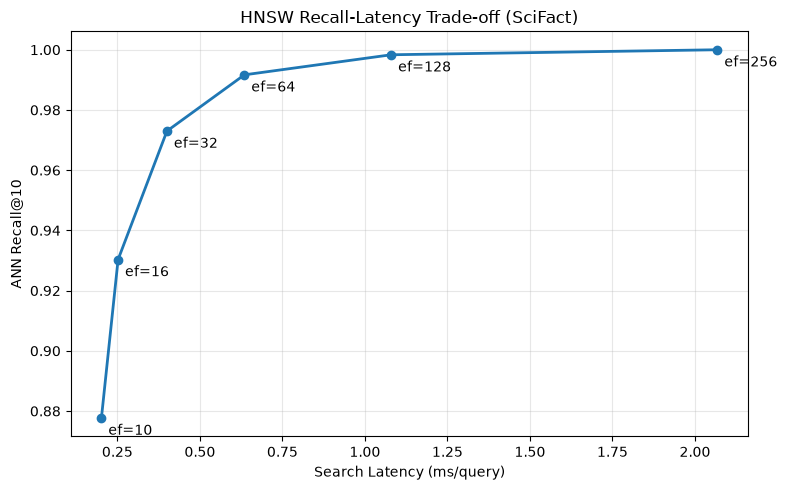

Saved to: C:\Users\weiting\Desktop\dense_retrieval\results\hnsw_recall_latency.png


In [14]:
import matplotlib.pyplot as plt

# Extract benchmark results
latencies = benchmark_df["Latency (ms/query)"]
recalls = benchmark_df["Recall@10"]
ef_values = benchmark_df["efSearch"]

plt.figure(figsize=(8, 5))

# Plot recall against latency
plt.plot(
    latencies,
    recalls,
    marker="o",
    linewidth=2
)

# Label each point with its efSearch value
for latency, recall, ef in zip(latencies, recalls, ef_values):
    plt.annotate(
        f"ef={ef}",
        (latency, recall),
        xytext=(5, -12),
        textcoords="offset points"
    )

plt.xlabel("Search Latency (ms/query)")
plt.ylabel("ANN Recall@10")
plt.title("HNSW Recall-Latency Trade-off (SciFact)")

plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save figure
figure_path = results_dir / "hnsw_recall_latency.png"
plt.savefig(figure_path, dpi=300)

plt.show()

print("Saved to:", figure_path)